# Echo State Networks (Reservoir Computing) from scratch

This notebook builds an **Echo State Network (ESN)** step by step using only NumPy (plus scikit-learn for the final linear fit). Run the cells from top to bottom; each one does one small thing and ends with a plot or printout.

**The idea.** A recurrent network with *random, fixed* weights (the "reservoir") turns an input signal into a rich, high-dimensional state. Only a simple *linear readout* on top of that state is trained.

$$h(t) = \tanh\big(W_{in}\,x(t) + W_{res}\,h(t-1) + \text{noise}\big), \qquad \hat y(t) = W_{out}\,h(t)$$

- $W_{in}$ and $W_{res}$ are random and **never trained**.
- Only $W_{out}$ is trained, with ridge regression (a single linear solve, no backpropagation).

**Task:** one-step-ahead prediction of a sine wave. Given $x(t)$, predict $x(t+1)$.

**Hardware angle (last section):** fixed random weights can be stored in memristive crossbar arrays. Real devices vary and have limited conductance levels, so we test how the ESN copes with that.

## 0. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

plt.rcParams["figure.figsize"] = (9, 3)
plt.rcParams["axes.grid"] = True

## 1. Make the data

Input is a sine wave `x(t)`; the target is the same wave one step later, `x(t+1)`. We train on the first 700 points and test on the rest.

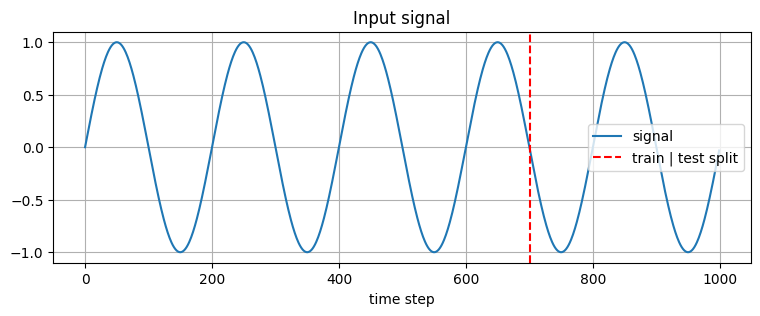

In [2]:
T = 1000
t = np.linspace(0, 10 * np.pi, T)
signal = np.sin(t).reshape(-1, 1)          # shape (T, 1)

X, y = signal[:-1], signal[1:]             # input x(t), target x(t+1)
split = 700

plt.plot(X[:, 0], label="signal")
plt.axvline(split, color="r", ls="--", label="train | test split")
plt.title("Input signal"); plt.xlabel("time step"); plt.legend(); plt.show()

## 2. Choose the hyperparameters

| Name | Meaning |
|---|---|
| `reservoir_dim` | number of reservoir neurons |
| `spectral_radius` | largest eigenvalue magnitude of $W_{res}$; controls how long the memory of past inputs lasts (below 1 is the usual choice) |
| `sparsity` | fraction of reservoir weights that are exactly zero |
| `noise_level` | small noise added in every state update |
| `ridge_alpha` | regularization strength of the readout |
| `washout` | first steps to discard, while the reservoir forgets its arbitrary starting state |

In [3]:
input_dim       = 1
reservoir_dim   = 300
spectral_radius = 0.9
sparsity        = 0.9
noise_level     = 0.001
ridge_alpha     = 1e-4
washout         = 50

## 3. Build the random reservoir

`W_in` connects the input to every neuron. `W_res` connects neurons to each other. We make `W_res` sparse, then rescale it so its spectral radius equals the value we chose.

W_in  shape: (300, 1)
W_res shape: (300, 300)
non-zero fraction in W_res: 0.100
spectral radius of W_res  : 0.900


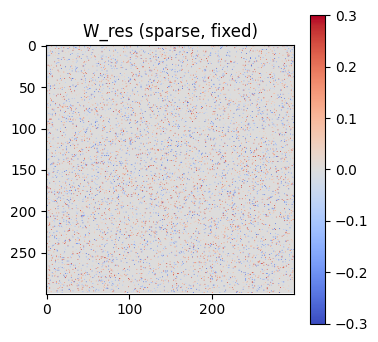

In [4]:
def make_reservoir(rng, input_dim, reservoir_dim, spectral_radius, sparsity):
    W_in = rng.uniform(-1, 1, (reservoir_dim, input_dim))

    W = rng.uniform(-1, 1, (reservoir_dim, reservoir_dim))
    W[rng.rand(reservoir_dim, reservoir_dim) < sparsity] = 0.0   # sparsify

    largest = np.max(np.abs(np.linalg.eigvals(W)))
    W_res = W * (spectral_radius / largest)                      # rescale
    return W_in, W_res

rng = np.random.RandomState(42)
W_in, W_res = make_reservoir(rng, input_dim, reservoir_dim, spectral_radius, sparsity)

print("W_in  shape:", W_in.shape)
print("W_res shape:", W_res.shape)
print("non-zero fraction in W_res: %.3f" % np.mean(W_res != 0))
print("spectral radius of W_res  : %.3f" % np.max(np.abs(np.linalg.eigvals(W_res))))

plt.figure(figsize=(4, 4)); plt.imshow(W_res, cmap="coolwarm", vmin=-0.3, vmax=0.3)
plt.title("W_res (sparse, fixed)"); plt.grid(False); plt.colorbar(); plt.show()

## 4. Drive the reservoir and collect its states

For each time step we apply the update equation. The result is a matrix of states with one row per time step and one column per neuron. **This is the only place the input signal enters.**

states shape: (999, 300)


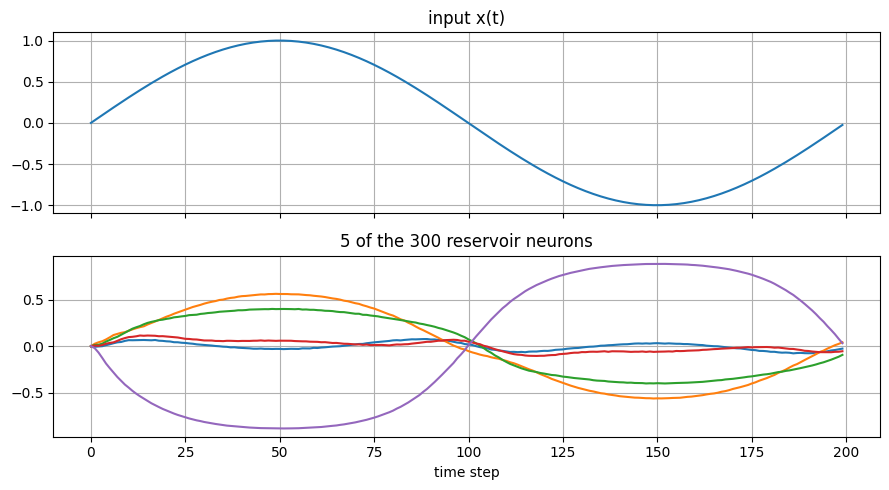

In [5]:
def run_reservoir(X, W_in, W_res, noise_level, rng):
    h = np.zeros(W_res.shape[0])
    states = []
    for x in X:
        h = np.tanh(W_in @ x + W_res @ h + noise_level * rng.randn(len(h)))
        states.append(h)
    return np.array(states)                 # shape (T, reservoir_dim)

noise_rng = np.random.RandomState(1)
states = run_reservoir(X, W_in, W_res, noise_level, noise_rng)
print("states shape:", states.shape)

fig, ax = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
ax[0].plot(X[:200, 0]); ax[0].set_title("input x(t)")
ax[1].plot(states[:200, :5]); ax[1].set_title("5 of the 300 reservoir neurons")
ax[1].set_xlabel("time step"); plt.tight_layout(); plt.show()

## 5. Train the readout (the only trained part)

Fit a ridge regression from reservoir states to the target. We skip the first `washout` states, because the reservoir starts from zero and needs a little time to settle.

In [6]:
states_train = states[washout:split]
y_train      = y[washout:split]

readout = Ridge(alpha=ridge_alpha)
readout.fit(states_train, y_train)
print("readout weights:", readout.coef_.shape)

readout weights: (300,)


## 6. Predict and evaluate

We use **NMSE** (normalized mean squared error): the mean squared error divided by the variance of the target. 0 is perfect, 1 is no better than predicting the mean.

> **Shape gotcha:** `readout.predict` can return shape `(N,)` while the target has shape `(N, 1)`. Subtracting them silently broadcasts to an `(N, N)` matrix and gives a wrong error (around 2). Always reshape the prediction to the target's shape first.

Test NMSE: 4.903e-07


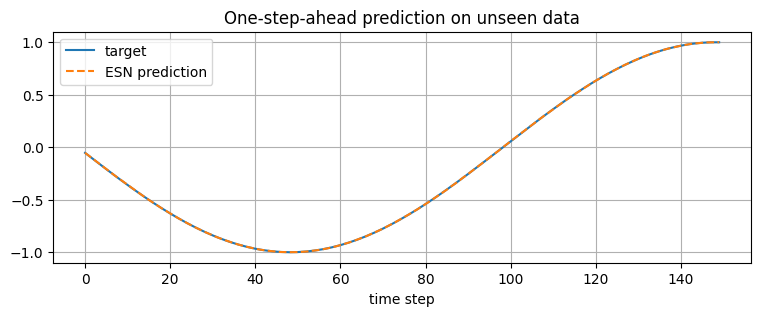

In [7]:
def nmse(pred, target):
    pred = np.asarray(pred).reshape(target.shape)       # avoid the broadcasting trap
    return np.mean((pred - target) ** 2) / np.var(target)

states_test = states[split:]
y_test      = y[split:]
y_pred      = readout.predict(states_test)

print("Test NMSE: %.3e" % nmse(y_pred, y_test))

plt.plot(y_test[:150, 0], label="target")
plt.plot(np.asarray(y_pred).reshape(-1)[:150], "--", label="ESN prediction")
plt.title("One-step-ahead prediction on unseen data"); plt.xlabel("time step"); plt.legend(); plt.show()

## 7. Experiment: what does the spectral radius do?

Rebuild the reservoir for several spectral radii and measure the test error. Intuition: a very small radius forgets the past quickly, so the reservoir has little memory.

spectral radius 0.1   -> NMSE 2.202e-05
spectral radius 0.3   -> NMSE 3.110e-06
spectral radius 0.5   -> NMSE 1.222e-06
spectral radius 0.7   -> NMSE 7.760e-07
spectral radius 0.9   -> NMSE 4.903e-07
spectral radius 0.99  -> NMSE 4.588e-07
spectral radius 1.2   -> NMSE 2.067e-07


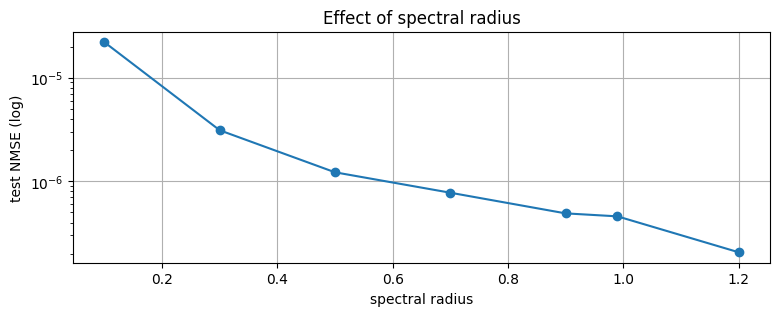

In [8]:
def evaluate(W_in, W_res, seed=1, train_W_res=None):
    # Run the reservoir, train the readout, return the test NMSE.
    # If train_W_res is given, the readout is trained on THAT reservoir
    # but tested on W_res (a train/deploy mismatch).
    r = np.random.RandomState(seed)
    s_test_res = run_reservoir(X, W_in, W_res, noise_level, r)
    s_train_res = s_test_res if train_W_res is None else \
        run_reservoir(X, W_in, train_W_res, noise_level, np.random.RandomState(seed + 100))
    ro = Ridge(alpha=ridge_alpha).fit(s_train_res[washout:split], y[washout:split])
    return nmse(ro.predict(s_test_res[split:]), y[split:])

radii = [0.1, 0.3, 0.5, 0.7, 0.9, 0.99, 1.2]
scores = []
for sr in radii:
    Wi, Wr = make_reservoir(np.random.RandomState(42), input_dim, reservoir_dim, sr, sparsity)
    scores.append(evaluate(Wi, Wr))
    print(f"spectral radius {sr:<5} -> NMSE {scores[-1]:.3e}")

plt.semilogy(radii, scores, "o-"); plt.xlabel("spectral radius"); plt.ylabel("test NMSE (log)")
plt.title("Effect of spectral radius"); plt.show()

**What to notice:** the smallest radius (0.1) is clearly the worst, and the error drops as the radius approaches 1. Even 1.2 works here because the sine input is strong enough to keep driving the reservoir, but this is an easy task. On harder tasks a radius above 1 is risky, so treat "below 1" as the safe default.

## 8. Hardware-aware experiment: device variation and limited levels

In a memristive crossbar, the reservoir weights are stored as device conductances. Two real-world issues:

1. **Device-to-device variation:** each stored weight is off by a random relative error.
2. **Limited conductance levels:** a device can only hold a few distinct values, so weights are quantized.

We test both on `W_res`, in two scenarios:

- **Mismatch:** the readout was trained on the *ideal* reservoir but runs on the *noisy* one.
- **Calibrated:** the readout is trained on the *same* imperfect reservoir it will run on (in-situ training of only the readout, which is cheap for an ESN).

Results are averaged over 5 random draws.

variation sigma=0    mismatch NMSE=4.93e-07   calibrated NMSE=5.14e-07
variation sigma=0.05 mismatch NMSE=5.96e-05   calibrated NMSE=5.16e-07
variation sigma=0.1  mismatch NMSE=2.32e-04   calibrated NMSE=5.17e-07
variation sigma=0.2  mismatch NMSE=9.03e-04   calibrated NMSE=5.18e-07
variation sigma=0.3  mismatch NMSE=2.05e-03   calibrated NMSE=5.19e-07
variation sigma=0.5  mismatch NMSE=6.50e-03   calibrated NMSE=4.42e-07


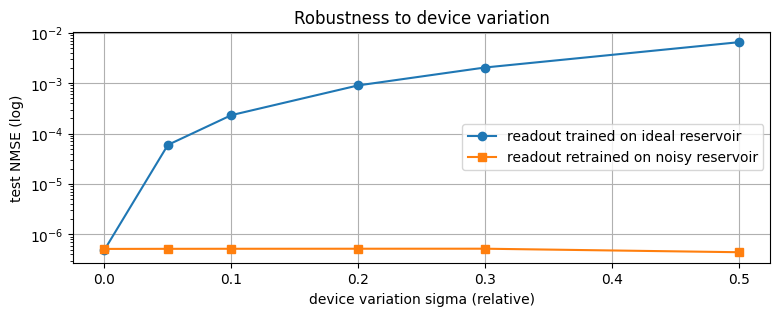

In [9]:
def perturb(W, sigma, rng):
    # multiplicative Gaussian device variation: w -> w * (1 + sigma * N(0,1))
    return W * (1 + sigma * rng.randn(*W.shape))

def quantize(W, levels):
    # snap weights to `levels` uniform steps per polarity (zeros stay zero)
    m = np.max(np.abs(W))
    return np.round(W / m * levels) / levels * m

sigmas = [0, 0.05, 0.1, 0.2, 0.3, 0.5]
mismatch, calibrated = [], []
for s in sigmas:
    mm, cal = [], []
    for k in range(5):
        Wp = perturb(W_res, s, np.random.RandomState(100 + k))
        mm.append(evaluate(W_in, Wp, seed=k, train_W_res=W_res))
        cal.append(evaluate(W_in, Wp, seed=k))
    mismatch.append(np.mean(mm)); calibrated.append(np.mean(cal))
    print(f"variation sigma={s:<4} mismatch NMSE={mismatch[-1]:.2e}   calibrated NMSE={calibrated[-1]:.2e}")

plt.semilogy(sigmas, mismatch, "o-", label="readout trained on ideal reservoir")
plt.semilogy(sigmas, calibrated, "s-", label="readout retrained on noisy reservoir")
plt.xlabel("device variation sigma (relative)"); plt.ylabel("test NMSE (log)")
plt.title("Robustness to device variation"); plt.legend(); plt.show()

**What to notice:** when the readout was trained on the ideal reservoir (mismatch), the error grows steadily with device variation. When the readout is retrained on the imperfect reservoir (calibrated), the error stays essentially flat. Because only the readout is trained, this recalibration is cheap.

 1 levels per polarity -> NMSE 3.905e-07
 2 levels per polarity -> NMSE 3.941e-07
 4 levels per polarity -> NMSE 4.764e-07
 8 levels per polarity -> NMSE 4.917e-07
16 levels per polarity -> NMSE 4.788e-07
32 levels per polarity -> NMSE 4.911e-07


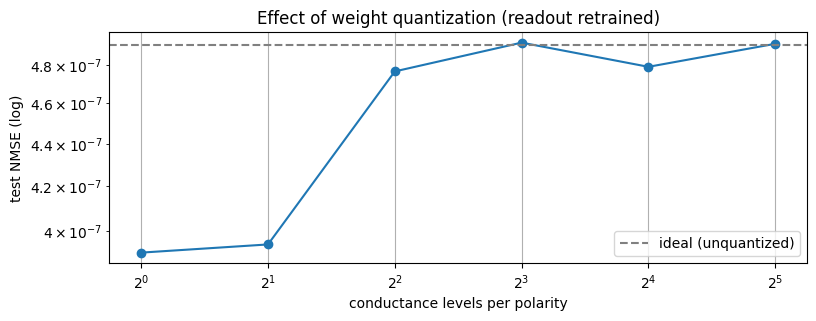

In [10]:
levels_list = [1, 2, 4, 8, 16, 32]
q_scores = []
for L in levels_list:
    Wq = quantize(W_res, L)
    q_scores.append(evaluate(W_in, Wq))
    print(f"{L:>2} levels per polarity -> NMSE {q_scores[-1]:.3e}")

plt.semilogy(levels_list, q_scores, "o-"); plt.xscale("log", base=2)
plt.axhline(evaluate(W_in, W_res), color="gray", ls="--", label="ideal (unquantized)")
plt.xlabel("conductance levels per polarity"); plt.ylabel("test NMSE (log)")
plt.title("Effect of weight quantization (readout retrained)"); plt.legend(); plt.show()